# Baseline CNN with 10-Fold Cross-Validation
### How stable is a small CNN trained from scratch, and does it beat colour alone?

**Why we are doing this:** In our EDA notebook, a Random Forest trained only on colour histograms reached a macro-F1 of '0.77' on a single data split. In this notebook, we train a small convolutional neural network ('SimpleCNN') from scratch and test how reliable it really is using 10-fold stratified cross-validation. By looking at the average Macro-AUC and standard deviation ('Mean ± Std') across all 10 folds, we can see how much the model's score jumps around depending on the split and compare it fairly against the colour-only baseline.

---

### Procedure

1. **Splitting the Data into Development and Holdout Test Sets:**
   - Using our team's shared 'split_dataset(seed=42)' function from 'src/data_utils.py', the dataset is split into 'train' (1764), 'val' (378) and 'test' (382) images.
   - We combine 'train' and 'val' into a 2,142 image development pool for cross-validation and final model training.
   - The 382 'test' images "stay completely locked away" during all 10 folds and final training—they are only evaluated once at the very end (Section 6).

2. **10-Fold Stratified Cross-Validation (Runs 1 to 10):**
   - We split the 2,142 development images into 10 stratified folds.
   - In each round, 9 folds (90% of the data) are used for training and 1 fold (10%) is used for validation.
   - Every fold starts with a brand-new 'SimpleCNN' trained from scratch, and its RGB normalization values and class weights are computed using only that fold's training images so nothing leaks from validation.
   - We also run the Colour Random Forest on the exact same 10 folds as a fair benchmark.

3. **Checking Model Stability:**
   - For each fold, we record the best validation Macro-AUC, along with Macro-F1 and the best epoch.
   - Summarizing these 10 runs as 'Mean ± Std' shows how consistent the CNN is across different data splits.

4. **Training the Final Model on All Development Data (Run 11):**
   - Once cross-validation is done, we initialise one last fresh 'SimpleCNN' and train it on all 2,142 development images(train + val).
   - Since there is no separate validation set here, we set the number of epochs to the average best epoch found across the 10 CV runs.

5. **Final Evaluation on the Holdout Test Set:**
   - Finally, we evaluate this final CNN (and a full-dev Colour Random Forest) on the untouched 382 image holdout test set, reporting Macro-AUC, Macro-F1, accuracy, per-class metrics and the confusion matrix.

### Hardware & Setup Note

- All 11 CNN training runs (10 cross-validation training runs + 1 final run) and evaluations are run on CPU with a fixed random seed (SEED = 42) so the results are reproducible.





## 1. Setup

The project root directory is resolved automatically so the notebook runs on any machine, shared utilities (`CLASSES`, `split_dataset`, `load_image`, and `color_histogram`) are imported from `src/data_utils.py`, and `SEED = 42` is fixed for reproducible splits and model initialization on CPU.



In [1]:
import sys, time, copy, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    f1_score, accuracy_score, roc_auc_score,
    classification_report, confusion_matrix
)

# 1. Fix random seeds so results are repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Force CPU execution as required
DEVICE = "cpu"

# 3. Resolve project root (notebooks/ -> trashnet-ml-project/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.append(str(ROOT))

# 4. Import shared utilities from src/data_utils.py (left untouched)
from src.data_utils import CLASSES, split_dataset, load_image, color_histogram

# 5. Create output directories for 10-fold plots and saved checkpoints
FIG_DIR = ROOT / "reports" / "figures" / "10fold"
MODEL_DIR = ROOT / "models" / "10fold"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
print("Project root :", ROOT)
print("Device       :", DEVICE)
print("Classes      :", CLASSES)


Project root : c:\SuvviNacka\Machine_learning\GroupProjekt\trashnet-ml-project
Device       : cpu
Classes      : ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


## 2. Data and 10 Folds

The team's shared 70/15/15 split is loaded using `split_dataset(seed=42)` so the setup matches the rest of the project:

- **Development set (`train + val`):** The original training (`1,764`) and validation (`378`) splits are combined into one development pool of 2,142 images for 10-fold cross-validation and final model training.
- **Holdout test set (`test`):** The remaining 382 images stay completely locked away from all 10 folds and final training, and are only evaluated once in Section 6.

`StratifiedKFold` divides the 2,142 development images into 10 folds while preserving the exact same class proportions in every fold (preventing rare classes like `trash` from being underrepresented in any split). Since 2,142 does not divide evenly by 10, two validation folds contain 215 images and the other eight contain 214 images.

Finally, to speed up training on CPU, all 2,524 RGB images are preloaded into RAM once up front instead of reading them from disk every epoch.


In [2]:
# 1. Load the exact shared split from src/data_utils.py
train, val, test = split_dataset(seed=SEED)
assert (len(train), len(val), len(test)) == (1764, 378, 382), "Unexpected split sizes!"

# 2. Combine train + val for 10-fold CV; keep `test` completely locked
dev_items = train + val
dev_labels = [lbl for _, lbl in dev_items]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

# 3. Create 10 stratified folds (each fold keeps exact class proportions)
N_SPLITS = 10
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(dev_items, dev_labels))

print(f"Development pool (10-fold CV) : {len(dev_items)} images")
print(f"Locked test set (untouched)   : {len(test)} images")
print(f"Fold 1 split sizes            : train = {len(FOLDS[0][0])}, val = {len(FOLDS[0][1])}")

# 4. Preload full-resolution RGB images into RAM (~1.5 GB) for faster CPU training
print("\nPreloading images into RAM...")
t0 = time.time()
IMAGE_CACHE = {p: Image.open(p).convert("RGB") for p, _ in (dev_items + test)}
print(f"Cached {len(IMAGE_CACHE)} images in {time.time() - t0:.1f} s.")

def open_rgb(path):
    """Return the pre-decoded 512 x 384 RGB image from RAM."""
    return IMAGE_CACHE[path]


Development pool (10-fold CV) : 2142 images
Locked test set (untouched)   : 382 images
Fold 1 split sizes            : train = 1927, val = 215

Preloading images into RAM...
Cached 2524 images in 2.2 s.


### Observations from Data Split & Caching (Section 2)

- **Dataset split verified:** split_dataset(seed=42) produced 1,764 training images, 378 validation images, and 382 test images, giving 2,524 deduplicated images in total.
- **Development set:** The training and validation sets were combined, resulting in 2,142 images for cross-validation.
- **Stratified folds:** The 2,142 development images were divided into ten folds. Two folds contain 215 validation images and eight contain 214 validation images. Stratification keeps the class distributions approximately consistent across folds.
- The 382 image holdout test set is excluded from crossvalidation, model training and model selection. It is reserved for the final evaluation after development and training are complete.
- **RAM caching:** Images are preloaded to reduce repeated disk access during CPU training.

## 3. Preprocessing and Model

### Preprocessing and PyTorch Dataset

This cell defines the image preprocessing helpers called inside each training fold. To prevent data leakage, RGB channel normalization (mean, std) is always calculated using only the training images of the active fold, never the validation fold or the locked test set.

- 'compute_mean_std()': computes the per-channel RGB mean and standard deviation from a random sample of up to 600 training images in the current fold.
- 'build_transforms()': builds data augmentation (random resized crops, flips, rotations, and slight colour jitter) for training, and deterministic resizing + normalization for validation and testing.
- 'TrashDataset': wraps image paths and labels into a PyTorch 'Dataset' so 'DataLoader' can feed batches into the CNN.

Note: Here we are defining helper functions and the dataset class for Sections 5 and 6, so it produces no printed output.


In [3]:
IMG_PX = 128

def compute_mean_std(items, n=600):
    """Compute per-channel RGB mean and std on training fold images only."""
    resize = T.Resize((IMG_PX, IMG_PX))
    subset = random.sample(items, min(n, len(items)))
    px = np.stack([
        np.asarray(resize(open_rgb(p)), dtype=np.float32) / 255.0
        for p, _ in subset
    ])
    return px.mean(axis=(0, 1, 2)), px.std(axis=(0, 1, 2))

def build_transforms(mean, std):
    """Create augmented training transforms and clean evaluation transforms for one fold."""
    train_tf = T.Compose([
        T.RandomResizedCrop(IMG_PX, scale=(0.8, 1.0), ratio=(3/4, 4/3)),
        T.RandomHorizontalFlip(),
        T.RandomVerticalFlip(),
        T.RandomRotation(20),
        T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
        T.ToTensor(),
        T.Normalize(mean.tolist(), std.tolist()),
    ])
    eval_tf = T.Compose([
        T.Resize((IMG_PX, IMG_PX)),
        T.ToTensor(),
        T.Normalize(mean.tolist(), std.tolist()),
    ])
    return train_tf, eval_tf

class TrashDataset(Dataset):
    """PyTorch Dataset returning (normalized tensor image, class index)."""
    def __init__(self, items, tf):
        self.items = items
        self.tf = tf

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, label = self.items[i]
        return self.tf(open_rgb(path)), CLASS_TO_IDX[label]


### Baseline CNN Architecture (`SimpleCNN`)

A compact 4-block convolutional network trained from scratch (`390,918` trainable parameters):

* **Feature extractor:** 4 repeated `Conv2d → BatchNorm → ReLU → MaxPool` blocks (`32 → 64 → 128 → 256` channels) that gradually learn edges, textures, and shapes while shrinking spatial resolution (`128×128 → 8×8`).
* **Classifier head:** Global average pooling (`AdaptiveAvgPool2d(1)`), `Dropout(0.15)` to reduce overfitting on a small dataset, and a final linear layer outputting scores for the 6 trash categories.



In [4]:
def conv_block(in_c, out_c):
    """Standard CNN building block: Conv2d -> BatchNorm -> ReLU -> MaxPool."""
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_c),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    """Small 4-block CNN trained from scratch (390,918 parameters)."""
    def __init__(self, n_classes=len(CLASSES)):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.15),
            nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))

print("Trainable parameters:", f"{sum(p.numel() for p in SimpleCNN().parameters()):,}")


Trainable parameters: 390,918


## 4. Training One Fold

### Running One Pass Over a DataLoader (`run_epoch`)

Defining a reusable helper function for a single epoch, first avoids repeating the exact same training and validation batch loop across all 10 cross-validation folds (Section 5) and the final model training run (Section 6). `run_epoch()` processes one full pass over `train_loader` or `val_loader`, updates model weights when `train_mode=True`, and returns `(avg_loss, macro_f1, macro_auc)`.




In [5]:
def run_epoch(model, loader, criterion, optimizer=None, train_mode=True):
    """Run one pass over `loader` and return (avg_loss, macro_f1, macro_auc)."""
    model.train(train_mode)
    total_loss = 0.0
    preds, labels, probs_list = [], [], []

    with torch.set_grad_enabled(train_mode):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = criterion(out, y)

            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            probs = torch.softmax(out, dim=1).detach().cpu().numpy()
            probs_list.append(probs)
            total_loss += loss.item() * len(y)
            preds.extend(out.argmax(dim=1).cpu().tolist())
            labels.extend(y.cpu().tolist())

    avg_loss = total_loss / len(loader.dataset)
    macro_f1 = f1_score(labels, preds, average="macro")
    macro_auc = roc_auc_score(labels, np.vstack(probs_list), multi_class="ovr", average="macro")
    return avg_loss, macro_f1, macro_auc


### Training a Single Fold from Scratch (`train_one_fold`)

Given fold_train (9 splits) and fold_val (1 split), train_one_fold() executes one complete training run:

1. Computes RGB normalization (mean, std) and balanced class weights strictly from fold_train to prevent leakage and handle class imbalance.
2. Initializes a fresh 'SimpleCNN' and 'Adam(lr=0.002)' optimizer.
3. Trains for up to 50 epochs (stopping early if validation AUC does not improve for 12 epochs), saves the best model weights to the 'models/10fold/' folder, and logs the metrics for each epoch.

Note: Here we are defining only the 'train_one_fold()' function, so there is no output.




In [6]:
MAX_EPOCHS = 50
PATIENCE = 12

def train_one_fold(fold_num, fold_train, fold_val):
    """Train a fresh SimpleCNN on one fold and save its best checkpoint."""
    # 1. Leak-free normalization and DataLoaders
    mean, std = compute_mean_std(fold_train)
    train_tf, eval_tf = build_transforms(mean, std)

    train_loader = DataLoader(TrashDataset(fold_train, train_tf), batch_size=32, shuffle=True, num_workers=0)
    val_loader   = DataLoader(TrashDataset(fold_val, eval_tf), batch_size=64, shuffle=False, num_workers=0)

    # 2. Class weights from fold_train only (handles class imbalance)
    y_tr_idx = [CLASS_TO_IDX[l] for _, l in fold_train]
    weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_tr_idx)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32).to(DEVICE))

    # 3. Fresh model & optimizer for this fold
    torch.manual_seed(SEED + fold_num)
    model = SimpleCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)

    best_auc, best_f1, best_epoch = 0.0, 0.0, 0
    best_state = None
    wait = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_f1, tr_auc = run_epoch(model, train_loader, criterion, optimizer, train_mode=True)
        va_loss, va_f1, va_auc = run_epoch(model, val_loader, criterion, train_mode=False)

        history.append({
            "fold": fold_num, "epoch": epoch,
            "train_loss": tr_loss, "val_loss": va_loss,
            "train_f1": tr_f1, "val_f1": va_f1,
            "train_auc": tr_auc, "val_auc": va_auc
        })

        # Track best validation Macro-AUC (and record corresponding Macro-F1)
        if va_auc > best_auc:
            best_auc, best_f1, best_epoch = va_auc, va_f1, epoch
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"  Early stopping at epoch {epoch} (best epoch: {best_epoch})")
                break

        if epoch == 1 or epoch % 10 == 0:
            print(f"  Epoch {epoch:2d} | val AUC {va_auc:.3f} | val F1 {va_f1:.3f}")

    # 4. Save best fold weights + normalization stats
    torch.save({
        "state_dict": best_state,
        "mean": mean.tolist(),
        "std": std.tolist(),
        "best_epoch": best_epoch
    }, MODEL_DIR / f"baseline_cnn_fold{fold_num}.pt")

    return {"best_auc": best_auc, "best_f1": best_f1, "best_epoch": best_epoch}, history


## 5. 10-fold cross-validation (CNN and colour model)
### Precompute colour histograms for the Random Forest benchmark
To keep the comparison fair, we evaluate the Colour Random Forest on the exact same 10 folds as the CNN. We extract the 128-bin HSV histograms once up front so the Random Forest runs in seconds inside the loop.


In [7]:
# Extract 128-bin HSV histograms once using your shared src/data_utils.py functions
print("Extracting HSV colour histograms for benchmark...")
DEV_HIST = {p: color_histogram(load_image(p)) for p, _ in dev_items}
TEST_HIST = {p: color_histogram(load_image(p)) for p, _ in test}

def eval_rf_fold(fold_train, fold_val):
    """Train Colour Random Forest on 9 training folds and score on 1 validation fold."""
    X_tr = np.array([DEV_HIST[p] for p, _ in fold_train])
    y_tr = [CLASS_TO_IDX[l] for _, l in fold_train]
    X_va = np.array([DEV_HIST[p] for p, _ in fold_val])
    y_va = [CLASS_TO_IDX[l] for _, l in fold_val]

    # Balanced class weights match the CNN's weighted loss
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
    rf.fit(X_tr, y_tr)

    probs = rf.predict_proba(X_va)
    preds = probs.argmax(axis=1)
    auc = roc_auc_score(y_va, probs, multi_class="ovr", average="macro")
    f1 = f1_score(y_va, preds, average="macro")
    return auc, f1

print("Histogram extraction complete.")


Extracting HSV colour histograms for benchmark...
Histogram extraction complete.


### Run All 10 Folds (Training Runs 1 to 10)

The loop below runs through all 10 stratified folds. In every fold:
1. 'eval_rf_fold()' trains and evaluates the 'Colour Random Forest' on the 128-bin HSV histograms.
2. 'train_one_fold()' initializes a fresh 'SimpleCNN' from scratch on the 9 training splits and evaluates it on the 1 held-out validation split.

Note: On CPU, each fold took about 40 to 73 minutes, and all 10 folds took about 8.4 hours (504.8 minutes) in total.



In [8]:
fold_results = []
all_histories = []
cv_start = time.time()

for fold_idx, (tr_idx, va_idx) in enumerate(FOLDS, start=1):
    fold_start = time.time()
    print(f"\n{'='*55}\nFOLD {fold_idx} / {N_SPLITS}  (Train: {len(tr_idx)} | Val: {len(va_idx)})\n{'='*55}")

    # Slice the 9 training folds and 1 validation fold
    fold_train = [dev_items[i] for i in tr_idx]
    fold_val   = [dev_items[i] for i in va_idx]

    # 1. Evaluate Colour Random Forest benchmark on this fold
    rf_auc, rf_f1 = eval_rf_fold(fold_train, fold_val)

    # 2. Train & evaluate fresh SimpleCNN on this fold
    cnn_stats, hist = train_one_fold(fold_idx, fold_train, fold_val)
    all_histories.extend(hist)

    mins = (time.time() - fold_start) / 60
    print(f"--> Fold {fold_idx} Summary | RF AUC: {rf_auc:.3f} (F1 {rf_f1:.3f}) | "
          f"CNN AUC: {cnn_stats['best_auc']:.3f} (F1 {cnn_stats['best_f1']:.3f}) | {mins:.1f} min")

    # Save fold metrics for stability analysis
    fold_results.append({
        "Fold": fold_idx,
        "RF_Val_AUC": rf_auc,
        "RF_Val_F1": rf_f1,
        "CNN_Val_AUC": cnn_stats["best_auc"],
        "CNN_Val_F1": cnn_stats["best_f1"],
        "Best_Epoch": cnn_stats["best_epoch"],
        "Minutes": round(mins, 1)
    })

print(f"\nAll 10 folds finished in {(time.time() - cv_start)/60:.1f} minutes.")



FOLD 1 / 10  (Train: 1927 | Val: 215)
  Epoch  1 | val AUC 0.801 | val F1 0.387
  Epoch 10 | val AUC 0.891 | val F1 0.571
  Epoch 20 | val AUC 0.931 | val F1 0.657
  Epoch 30 | val AUC 0.944 | val F1 0.706
  Epoch 40 | val AUC 0.934 | val F1 0.668
  Epoch 50 | val AUC 0.931 | val F1 0.697
--> Fold 1 Summary | RF AUC: 0.957 (F1 0.752) | CNN AUC: 0.950 (F1 0.741) | 45.1 min

FOLD 2 / 10  (Train: 1927 | Val: 215)
  Epoch  1 | val AUC 0.803 | val F1 0.379
  Epoch 10 | val AUC 0.888 | val F1 0.521
  Epoch 20 | val AUC 0.889 | val F1 0.587
  Epoch 30 | val AUC 0.923 | val F1 0.629
  Epoch 40 | val AUC 0.939 | val F1 0.701
  Epoch 50 | val AUC 0.946 | val F1 0.693
--> Fold 2 Summary | RF AUC: 0.951 (F1 0.728) | CNN AUC: 0.947 (F1 0.706) | 73.0 min

FOLD 3 / 10  (Train: 1928 | Val: 214)
  Epoch  1 | val AUC 0.843 | val F1 0.491
  Epoch 10 | val AUC 0.906 | val F1 0.557
  Epoch 20 | val AUC 0.925 | val F1 0.667
  Epoch 30 | val AUC 0.952 | val F1 0.659
  Epoch 40 | val AUC 0.943 | val F1 0.682

### Observations from 10-Fold Training Loop 
* **Consistent convergence across all 10 folds:** Every fold climbed smoothly from 0.76–0.84 validation Macro-AUC at Epoch 1 to 0.931–0.967 by peak epoch, with no collapsed or diverged runs.
* **Early stopping behavior:** Eight of the ten folds continued improving until epochs 41–50, while 'Fold 5'(stopped at epoch 45, best epoch 33) and 'Fold 9' (stopped at epoch 44, best epoch 32) triggered early stopping (PATIENCE = 12). Across all 10 folds, the average optimal epoch was 43.1 epochs(504.8 minutes total CPU runtime).


### Stability report: Average AUC ± Standard Deviation (`Mean ± Std`)
Here we summarize the 10 folds into Mean ± Standard Deviation, the key stability metric and plot both models side by side across folds and epochs.


,Fold,RF_Val_AUC,RF_Val_F1,CNN_Val_AUC,CNN_Val_F1,Best_Epoch,Minutes
0,1,0.957368,0.752459,0.950267,0.740897,43,45.1
1,2,0.951131,0.727575,0.947130,0.706163,41,73.0
2,3,0.963457,0.770421,0.966615,0.743191,46,53.1
3,4,0.951820,0.770688,0.954306,0.727698,48,50.4
4,5,0.969850,0.815391,0.945946,0.660990,33,45.7
5,6,0.964837,0.773070,0.952737,0.719266,48,52.7
6,7,0.956388,0.791590,0.957721,0.793393,45,50.2
7,8,0.940387,0.749685,0.945558,0.699081,45,51.0
8,9,0.966007,0.720208,0.950071,0.734173,32,43.9
9,10,0.944857,0.751641,0.931352,0.687190,50,39.7


10-FOLD CROSS-VALIDATION STABILITY SUMMARY (Mean ± Std)
Colour RF    | Macro-AUC: 0.957 ± 0.010 | Macro-F1: 0.762 ± 0.028
Baseline CNN | Macro-AUC: 0.950 ± 0.009 | Macro-F1: 0.721 ± 0.036


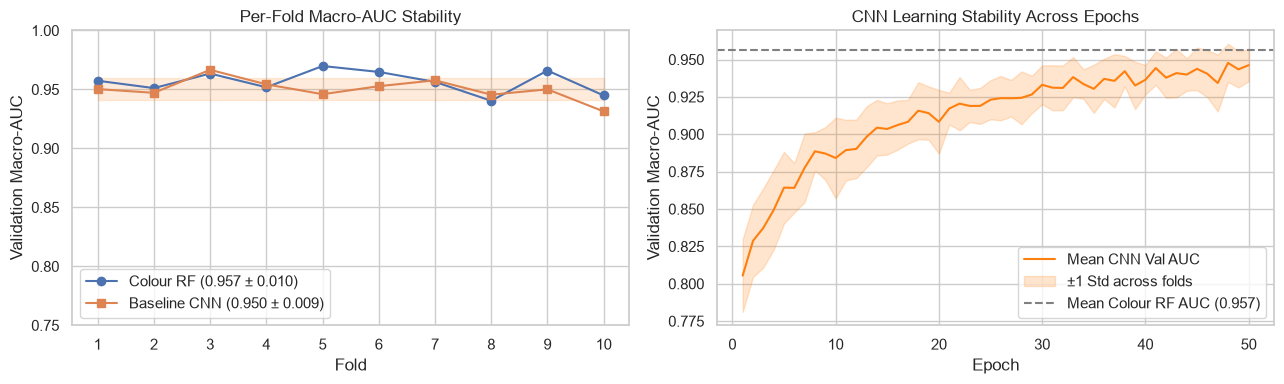

In [9]:
results_df = pd.DataFrame(fold_results)
results_df.to_csv(ROOT / "reports" / "10fold_cv_results.csv", index=False)
display(results_df)

# Compute Mean and Standard Deviation across the 10 folds
rf_auc_m, rf_auc_s   = results_df["RF_Val_AUC"].mean(), results_df["RF_Val_AUC"].std()
cnn_auc_m, cnn_auc_s = results_df["CNN_Val_AUC"].mean(), results_df["CNN_Val_AUC"].std()
rf_f1_m, rf_f1_s     = results_df["RF_Val_F1"].mean(), results_df["RF_Val_F1"].std()
cnn_f1_m, cnn_f1_s   = results_df["CNN_Val_F1"].mean(), results_df["CNN_Val_F1"].std()

print("=" * 60)
print("10-FOLD CROSS-VALIDATION STABILITY SUMMARY (Mean ± Std)")
print("=" * 60)
print(f"Colour RF    | Macro-AUC: {rf_auc_m:.3f} ± {rf_auc_s:.3f} | Macro-F1: {rf_f1_m:.3f} ± {rf_f1_s:.3f}")
print(f"Baseline CNN | Macro-AUC: {cnn_auc_m:.3f} ± {cnn_auc_s:.3f} | Macro-F1: {cnn_f1_m:.3f} ± {cnn_f1_s:.3f}")

# Create 2 side-by-side subplots: axes[0] (left) and axes[1] (right)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
folds = results_df["Fold"]

# --- Plot 1 (Left): Fold-by-Fold Validation Macro-AUC Stability ---
axes[0].plot(folds, results_df["RF_Val_AUC"], marker="o", label=f"Colour RF ({rf_auc_m:.3f} ± {rf_auc_s:.3f})")
axes[0].plot(folds, results_df["CNN_Val_AUC"], marker="s", label=f"Baseline CNN ({cnn_auc_m:.3f} ± {cnn_auc_s:.3f})")
axes[0].fill_between(folds, cnn_auc_m - cnn_auc_s, cnn_auc_m + cnn_auc_s, alpha=0.15, color="tab:orange")
axes[0].set_xticks(folds)
axes[0].set_ylim(0.75, 1.0)
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Validation Macro-AUC")
axes[0].set_title("Per-Fold Macro-AUC Stability")
axes[0].legend()

# --- Plot 2 (Right): Mean Validation AUC Curve ± 1 Std Across Epochs ---
hist_df = pd.DataFrame(all_histories)
agg = hist_df.groupby("epoch")["val_auc"].agg(["mean", "std"]).reset_index()

axes[1].plot(agg["epoch"], agg["mean"], color="tab:orange", label="Mean CNN Val AUC")
axes[1].fill_between(agg["epoch"], agg["mean"] - agg["std"], agg["mean"] + agg["std"], alpha=0.2, color="tab:orange", label="±1 Std across folds")
axes[1].axhline(rf_auc_m, color="grey", linestyle="--", label=f"Mean Colour RF AUC ({rf_auc_m:.3f})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Macro-AUC")
axes[1].set_title("CNN Learning Stability Across Epochs")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "10fold_stability_curves.png", dpi=150)
plt.show()


### Observations & Interpretation of 10-Fold Stability Results

1. **Consistent Macro-AUC across folds (Left graph):**
   - The Baseline CNN achieved a mean validation Macro-AUC of 0.950 ± 0.009, ranging from 0.931 in Fold 10 to 0.967 in Fold 3.
   - In the left plot, the orange CNN line stays flat inside a narrow shaded band (± 0.009), showing that its ranking performance is steady regardless of which split is used.

2. **Steady learning across epochs (Right graph):**
   - In the right plot, the mean CNN validation AUC climbs smoothly from 0.805 at Epoch 1 to 0.95 by Epoch 50 with a tight ± 1 Std band, gradually approaching the dashed 0.957 Colour Random Forest line.

3. **Higher fold-to-fold variation in Macro-F1:**
   - The CNN's mean Macro-F1 was 0.721 ± 0.036 (compared to 0.762 ± 0.028 for the Colour Random Forest).


4. **Comparison & key caveats:**
   - On average Macro-AUC, the Colour Random Forest (0.957 ± 0.010) and Baseline CNN (0.950 ± 0.009) are very close, while the Colour Random Forest leads on Macro-F1 (0.762 vs 0.721).
   - Because the 10 training folds overlap (sharing 89% of their images) and the best epoch was selected using each fold's validation AUC, the standard deviation reflects fold-to-fold spread rather than a strict confidence interval, and the CV scores may be slightly optimistic.



### Overfitting Check: Train vs. Validation Loss and Macro-AUC Across All Epochs

To check whether the CNN overfits on a small dataset, both training and validation curves(Cross-Entropy Loss and Macro-AUC) are plotted across all 50 epochs, averaged across the available folds at each epoch. (Mean ± 1 Std). If severe overfitting occurs, validation loss will start rising while training loss keeps dropping.



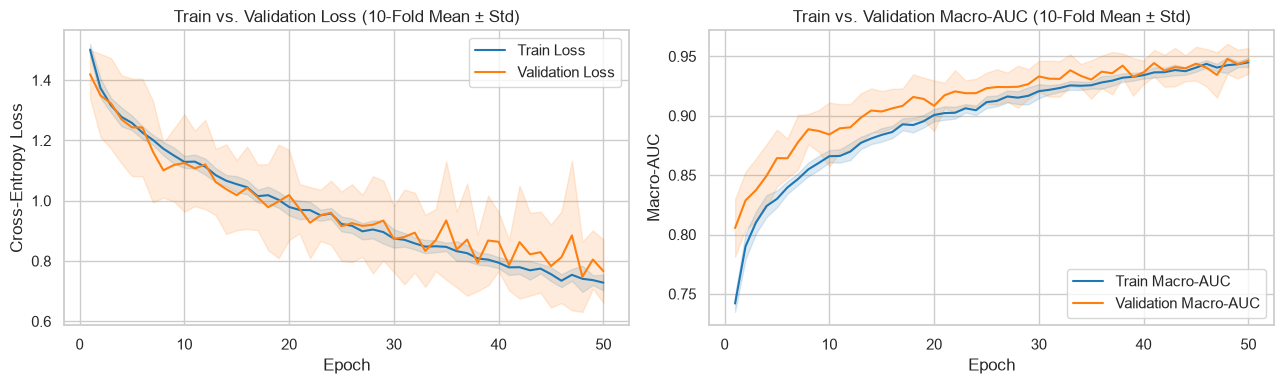

In [10]:
# Plot Train vs. Validation Loss and Macro-AUC across all 50 epochs (10-fold mean ± 1 std)
hist_df = pd.DataFrame(all_histories)
agg_ep = hist_df.groupby("epoch").agg(
    tr_loss_m=("train_loss", "mean"), tr_loss_s=("train_loss", "std"),
    va_loss_m=("val_loss", "mean"),   va_loss_s=("val_loss", "std"),
    tr_auc_m=("train_auc", "mean"),   tr_auc_s=("train_auc", "std"),
    va_auc_m=("val_auc", "mean"),     va_auc_s=("val_auc", "std"),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left subplot: Cross-Entropy Loss (Train vs. Validation)
axes[0].plot(agg_ep["epoch"], agg_ep["tr_loss_m"], label="Train Loss", color="tab:blue")
axes[0].fill_between(agg_ep["epoch"], agg_ep["tr_loss_m"] - agg_ep["tr_loss_s"], agg_ep["tr_loss_m"] + agg_ep["tr_loss_s"], alpha=0.15, color="tab:blue")
axes[0].plot(agg_ep["epoch"], agg_ep["va_loss_m"], label="Validation Loss", color="tab:orange")
axes[0].fill_between(agg_ep["epoch"], agg_ep["va_loss_m"] - agg_ep["va_loss_s"], agg_ep["va_loss_m"] + agg_ep["va_loss_s"], alpha=0.15, color="tab:orange")
axes[0].set(title="Train vs. Validation Loss (10-Fold Mean ± Std)", xlabel="Epoch", ylabel="Cross-Entropy Loss")
axes[0].legend()

# Right subplot: Macro-AUC (Train vs. Validation)
axes[1].plot(agg_ep["epoch"], agg_ep["tr_auc_m"], label="Train Macro-AUC", color="tab:blue")
axes[1].fill_between(agg_ep["epoch"], agg_ep["tr_auc_m"] - agg_ep["tr_auc_s"], agg_ep["tr_auc_m"] + agg_ep["tr_auc_s"], alpha=0.15, color="tab:blue")
axes[1].plot(agg_ep["epoch"], agg_ep["va_auc_m"], label="Validation Macro-AUC", color="tab:orange")
axes[1].fill_between(agg_ep["epoch"], agg_ep["va_auc_m"] - agg_ep["va_auc_s"], agg_ep["va_auc_m"] + agg_ep["va_auc_s"], alpha=0.15, color="tab:orange")
axes[1].set(title="Train vs. Validation Macro-AUC (10-Fold Mean ± Std)", xlabel="Epoch", ylabel="Macro-AUC")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "10fold_train_vs_val_curves.png", dpi=150)
plt.show()


### Observations: Training and Validation Curves 
Looking at both graphs across the training epochs shows how steadily the CNN learned. The curves show the mean and standard deviation across the folds that completed each epoch. Since Fold 5 and Fold 9 stopped early, the number of folds contributing to the averages decreases from 10 to 9 and then to 8 in the later epochs.

- **No severe overfitting (Left graph — Cross-Entropy Loss):** Both the blue training loss (1.51 → 0.73) and orange validation loss (1.41 → 0.77) decrease smoothly together across all 50 epochs. Because validation loss does not bend upward while training loss drops, the model is learning general visual features rather than memorizing the training photos.
- **Steady accuracy gain (Right graph — Macro-AUC):** Both curves climb quickly over the first 15 epochs and then level off smoothly around 0.95 Macro-AUC.
- **Why the validation curve sits slightly above the training curve:** Data augmentation (random crops, flips, rotations, and colour jitter) and Dropout(0.15) are active during training to make learning harder and prevent memorization, whereas validation runs on clean, unaugmented images with dropout turned off.



## 6. Final model and holdout test evaluation

### Prepare the final model

After completing the ten-fold cross-validation, we train one final 'SimpleCNN' from scratch using all 2,142 development images (train + val).

The number of training epochs is selected using the average best epoch across the ten cross-validation folds. In this experiment, the average best epoch is approximately 43.

The final model is initialized with new weights and is not one of the models trained during cross-validation.

The 382-image holdout test set is not used during this final training stage.



In [11]:
# 1. Calculate the average optimal epoch count from our 10 folds
optimal_epochs = int(round(results_df["Best_Epoch"].mean()))
print(f"Average best epoch across 10 folds: {results_df['Best_Epoch'].mean():.1f} -> Will train for {optimal_epochs} epochs")

# 2. Compute channel normalization (mean, std) from a 600-image sample of the development set
full_mean, full_std = compute_mean_std(dev_items)
full_train_tf, full_eval_tf = build_transforms(full_mean, full_std)

# 3. Create DataLoader for all 2,142 development images
full_train_loader = DataLoader(TrashDataset(dev_items, full_train_tf), batch_size=32, shuffle=True, num_workers=0)

# 4. Compute balanced class weights on all 2,142 development images
y_dev_idx = [CLASS_TO_IDX[l] for _, l in dev_items]
full_weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_dev_idx)
full_criterion = nn.CrossEntropyLoss(weight=torch.tensor(full_weights, dtype=torch.float32).to(DEVICE))

# 5. Initialize a fresh SimpleCNN and Adam optimizer
torch.manual_seed(SEED)
final_model = SimpleCNN().to(DEVICE)
final_optimizer = torch.optim.Adam(final_model.parameters(), lr=2e-3)
print("Full-data DataLoader and fresh final_model ready.")


Average best epoch across 10 folds: 43.1 -> Will train for 43 epochs
Full-data DataLoader and fresh final_model ready.


### Train and Save the Final CNN (`baseline_cnn_final_refit.pt`)

'final_model' is trained from scratch on all 2,142 development images for 'optimal_epochs' (43) epochs, and its trained weights and normalization statistics are saved to disk. (Takes 42 minutes on CPU)


In [12]:
refit_start = time.time()

for epoch in range(1, optimal_epochs + 1):
    tr_loss, tr_f1, tr_auc = run_epoch(final_model, full_train_loader, full_criterion, final_optimizer, train_mode=True)
    if epoch == 1 or epoch % 5 == 0 or epoch == optimal_epochs:
        print(f"  Final Refit Epoch {epoch:2d}/{optimal_epochs} | train AUC {tr_auc:.3f} | train F1 {tr_f1:.3f}")

# Save the final refitted model checkpoint
torch.save({
    "state_dict": final_model.state_dict(),
    "mean": full_mean.tolist(),
    "std": full_std.tolist(),
    "epochs": optimal_epochs
}, MODEL_DIR / "baseline_cnn_final_refit.pt")

print(f"\nFinal refit (Run #11) finished in {(time.time() - refit_start)/60:.1f} minutes.")


  Final Refit Epoch  1/43 | train AUC 0.728 | train F1 0.358
  Final Refit Epoch  5/43 | train AUC 0.830 | train F1 0.483
  Final Refit Epoch 10/43 | train AUC 0.867 | train F1 0.559
  Final Refit Epoch 15/43 | train AUC 0.896 | train F1 0.611
  Final Refit Epoch 20/43 | train AUC 0.904 | train F1 0.621
  Final Refit Epoch 25/43 | train AUC 0.919 | train F1 0.657
  Final Refit Epoch 30/43 | train AUC 0.926 | train F1 0.663
  Final Refit Epoch 35/43 | train AUC 0.928 | train F1 0.676
  Final Refit Epoch 40/43 | train AUC 0.939 | train F1 0.707
  Final Refit Epoch 43/43 | train AUC 0.940 | train F1 0.700

Final refit (Run #11) finished in 41.8 minutes.


### Observations from Final Full-Data Training

* **Smooth, steady convergence:** Training on all 2,142 development images (train + val) for the CV-selected optimal length of 43 epochs progressed smoothly from 0.728 train AUC (0.358 F1) at Epoch 1 up to 0.940 train AUC (0.700 F1)by Epoch 43 (41.8 minutes CPU runtime).
* * **Training scores align with CV validation scores:** The final training AUC (0.940) was measured with data augmentation and dropout active, so it is not directly comparable to validation AUC measured without those training effects, yet it closely matches the 10-fold CV validation average (0.950 ± 0.009).
* **Checkpoint saved:** The final model weights and normalization statistics (mean, std, computed from a random sample of up to 600 development images) are saved to 'models/10fold/baseline_cnn_final_refit.pt'.
* **Holdout test set kept untouched:** The 382 image locked test set remained completely excluded from all 10 cross-validation folds and from this final training run, ready for a single final evaluation.
* **Optimism caveat:** Because each CV fold selected its best epoch using its validation AUC, the CNN's CV scores may be slightly optimistic compared to the Colour Random Forest, which does not require epoch selection.





### Run Predictions on the 382-Image Holdout Test Set

Both models, the final 'SimpleCNN' and a 'Colour Random Forest' trained on all 2,142 development images are now evaluated once on the untouched 382 test images to collect predicted class probabilities and labels.


In [13]:
# 1. Get predicted probabilities from the final refitted CNN on the 382 test images
test_loader = DataLoader(TrashDataset(test, full_eval_tf), batch_size=64, shuffle=False, num_workers=0)
final_model.eval()

test_probs, test_preds, y_true = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        logits = final_model(x.to(DEVICE))
        probs = torch.softmax(logits, dim=1)
        test_probs.append(probs.cpu().numpy())
        test_preds.extend(logits.argmax(dim=1).cpu().tolist())
        y_true.extend(y.tolist())

test_probs = np.vstack(test_probs)
y_true = np.array(y_true)
y_pred = np.array(test_preds)

# 2. Train Colour Random Forest on all 2,142 dev images and predict on the same 382 test images
rf_full = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf_full.fit(np.array([DEV_HIST[p] for p, _ in dev_items]), [CLASS_TO_IDX[l] for _, l in dev_items])
rf_test_probs = rf_full.predict_proba(np.array([TEST_HIST[p] for p, _ in test]))
rf_test_pred  = rf_test_probs.argmax(axis=1)

print("Predictions on all 382 locked test images complete.")


Predictions on all 382 locked test images complete.


### Final Test Metrics, Classification Report, and Confusion Matrix

Macro-AUC, Macro-F1 and Accuracy are calculated on the 382 image holdout test set alongside the per-class classification report and confusion matrix to see which waste categories are classified accurately and where mistakes happen.

The locked test set was kept completely untouched throughout 10-fold cross-validation and final full-data training, and is evaluated here for the first time.


FINAL LOCKED TEST SET EVALUATION (382 UNTOUCHED IMAGES)
Colour RF    | Test Macro-AUC: 0.964 | Test Macro-F1: 0.803
Baseline CNN | Test Macro-AUC: 0.955 | Test Macro-F1: 0.746 | Accuracy: 0.767

Per-Class Classification Report (Locked Test Set):
              precision    recall  f1-score   support

   cardboard      0.944     0.836     0.887        61
       glass      0.697     0.816     0.752        76
       metal      0.697     0.742     0.719        62
       paper      0.829     0.756     0.791        90
     plastic      0.815     0.736     0.774        72
       trash      0.500     0.619     0.553        21

    accuracy                          0.767       382
   macro avg      0.747     0.751     0.746       382
weighted avg      0.779     0.767     0.770       382



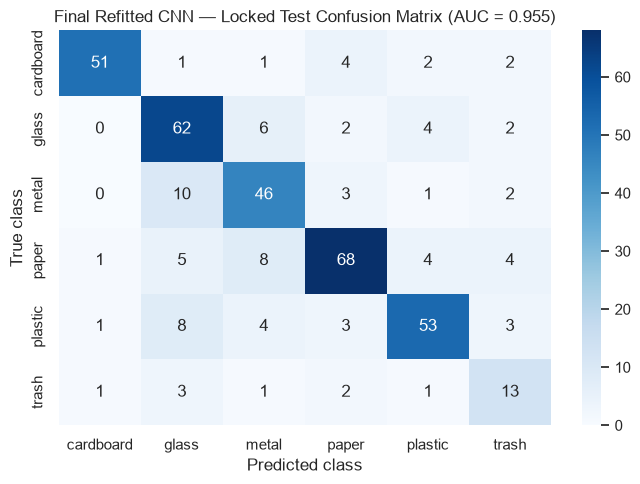

In [14]:
# 1. Print summary comparison on the locked 382 test images
cnn_test_auc = roc_auc_score(y_true, test_probs, multi_class="ovr", average="macro")
cnn_test_f1  = f1_score(y_true, y_pred, average="macro")
rf_test_auc  = roc_auc_score(y_true, rf_test_probs, multi_class="ovr", average="macro")
rf_test_f1   = f1_score(y_true, rf_test_pred, average="macro")

print("=" * 65)
print("FINAL LOCKED TEST SET EVALUATION (382 UNTOUCHED IMAGES)")
print("=" * 65)
print(f"Colour RF    | Test Macro-AUC: {rf_test_auc:.3f} | Test Macro-F1: {rf_test_f1:.3f}")
print(f"Baseline CNN | Test Macro-AUC: {cnn_test_auc:.3f} | Test Macro-F1: {cnn_test_f1:.3f} | Accuracy: {accuracy_score(y_true, y_pred):.3f}\n")

# 2. Detailed precision, recall, and F1 per trash category
print("Per-Class Classification Report (Locked Test Set):")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

# 3. Plot and save the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.title(f"Final Refitted CNN — Locked Test Confusion Matrix (AUC = {cnn_test_auc:.3f})")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.savefig(FIG_DIR / "10fold_final_test_confusion_matrix.png", dpi=150)
plt.show()


### Observations & Interpretation of Holdout Test Set Results

1. **Test performance matches the 10-fold CV estimate:**
   - On the 382 image holdout test set, the final 'SimpleCNN' achieved 0.955 Macro-AUC, 0.746 Macro-F1 and 76.7% accuracy (293 / 382 correct).
   - This aligns closely with the 10-fold CV validation averages (0.950 ± 0.009 Macro-AUC and 0.721 ± 0.036 Macro-F1), with a slight improvement from training the final model on all 2,142 development images.

2. **Per-class strengths & confusion matrix patterns:**
   - 'cardboard' is the easiest category to recognize (F1 = 0.887, 94.4% precision, 51 / 61 correctly classified) likely due to its distinct brown colour and corrugated texture.
   - Largest confusions: Looking at the off-diagonal cells of the confusion matrix, 10 'metal' items were predicted as 'glass', 8 'plastic' items as 'glass', and 8 'paper' items as 'metal' (likely influenced by bright studio highlights and surface reflections). Together, these three pairs account for 26 of the 89 total errors.
   - 'trash' remains the hardest category (F1 = 0.553): With only 21 test images and wide visual variety across miscellaneous waste, 13 were classified correctly, while 50.0% precision shows that several items from other categories were mislabeled as 'trash'.

3. **Benchmark comparison (Colour Random Forest vs. Baseline CNN):**
   - The 'Colour Random Forest' outperformed the scratch-trained CNN on the holdout test set, scoring 0.964 Macro-AUC vs 0.955 for the CNN and 0.803 Macro-F1 vs 0.746 for the CNN.
   - While small differences on 382 test images can partly reflect sample size, the pattern matches the 10-fold CV results. Because this Colour Random Forest was trained on all 2,142 development images (train + val) its test scores (0.964 Macro-AUC and 0.803 Macro-F1) are slightly higher than in the single-split EDA notebook (0.960 Macro-AUC and 0.792 Macro-F1, where it was trained on only 1,764 train images).



### Inspecting specific mistakes on the locked test set
 Inspecting concrete misclassified images (True → Predicted) reveals why errors happen—particularly on reflective 'metal' cans, transparent 'glass' and 'plastic' bottles and visually diverse 'trash' items.


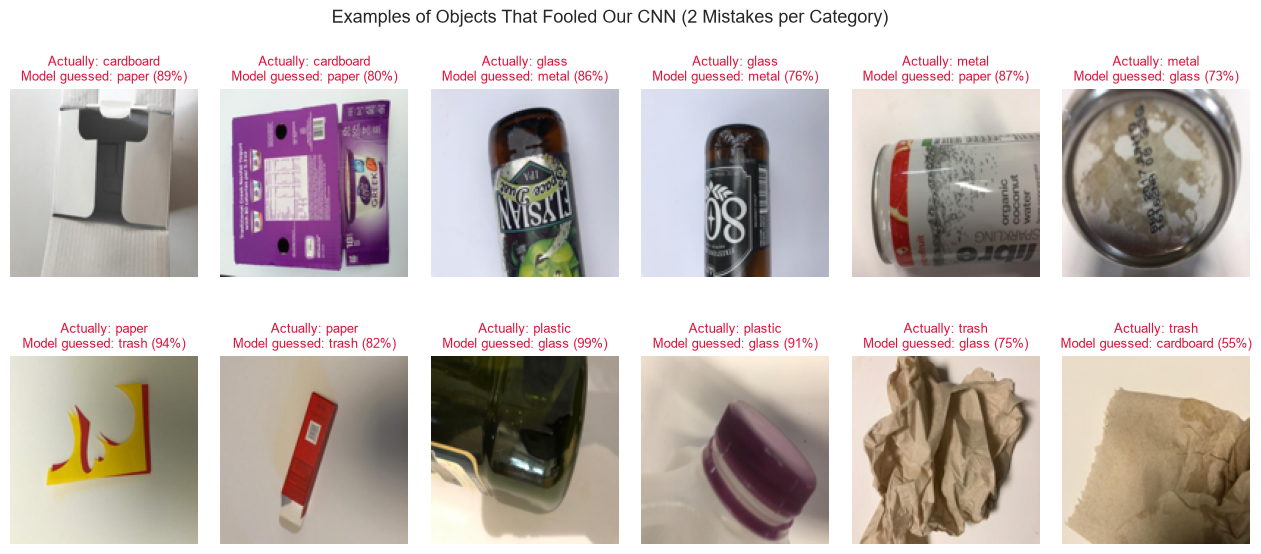

In [15]:
# Pick up to 2 misclassified test images from EACH of the 6 classes for a balanced and easy to read 
selected_idx = []
for cls_idx in range(len(CLASSES)):
    cls_wrong = np.flatnonzero((y_true == cls_idx) & (y_pred != y_true))
    # Sort by highest confidence so we see the clearest examples where the model was fooled
    cls_wrong = cls_wrong[np.argsort(-test_probs[cls_wrong, y_pred[cls_wrong]])]
    selected_idx.extend(cls_wrong[:2])

fig, axes = plt.subplots(2, 6, figsize=(16, 6.2))
for ax, idx in zip(axes.ravel(), selected_idx):
    img_path, _ = test[idx]
    ax.imshow(open_rgb(img_path).resize((128, 128)))
    conf = test_probs[idx, y_pred[idx]]
    ax.set_title(
        f"Actually: {CLASSES[y_true[idx]]}\nModel guessed: {CLASSES[y_pred[idx]]} ({conf:.0%})",
        color="crimson", fontsize=9.5, pad=6
    )
    ax.axis("off")

plt.suptitle("Examples of Objects That Fooled Our CNN (2 Mistakes per Category)", fontsize=13, y=0.98)
plt.subplots_adjust(top=0.86, hspace=0.35, wspace=0.12)
plt.savefig(FIG_DIR / "10fold_test_mistakes.png", dpi=150)
plt.show()


### Observations from Objects That Fooled the CNN 

Inspecting the specific test photos where the final CNN was most confidently wrong (2 per category) explains the patterns in the confusion matrix:

1. **White and printed packaging confuses 'cardboard' with 'paper' (top-left, cols 1–2):**
   - Standard TrashNet cardboard is plain brown, so white-coated (89%) and purple printed (80%) cardboard boxes are mistaken for 'paper'.
2. **Labels, reflections, and transparency blur 'glass', 'metal', and 'plastic' (top cols 3–6 & bottom cols 3–4):**
   - Dark 'glass' bottles with prominent labels are guessed as 'metal' (86%, 76%)a white-wrapped metal can is guessed as paper (87%), a shiny aluminum 'metal' can base looks like 'glass' (73%) and dark or translucent 'plastic' bottles are confidently mistaken for 'glass' (99%, 91%).
3. **Cut scraps, wrappers, and brown paper overlap with 'trash' and 'cardboard' (bottom cols 1–2 & 5–6):**
   - Brightly coloured cut 'paper' scraps and small cartons are guessed as 'trash' (94%, 82%), a crumpled 'trash' wrapper looks like 'glass' (75%), and a brown unbleached paper towel in 'trash' shares the tan colour of 'cardboard' ('55%').

**Key takeaway:** Because this small CNN was trained from scratch on only 2,142 development images, it relies heavily on overall colour and surface brightness rather than deeper material texture, which explains why pretrained transfer learning is needed next.


### Per-Category Comparison (Colour RF vs. CNN) and ROC Curves on the Holdout Test Set

To compare both models clearly across waste categories on the holdout test set:
* **Left:** Per-class F1-score comparing the 'Colour Random Forest' against the final 'SimpleCNN' across all six waste categories.
* **Right:** One-vs-Rest 'ROC curves' for each category, showing how the 0.955 Macro-AUC breaks down by material type.


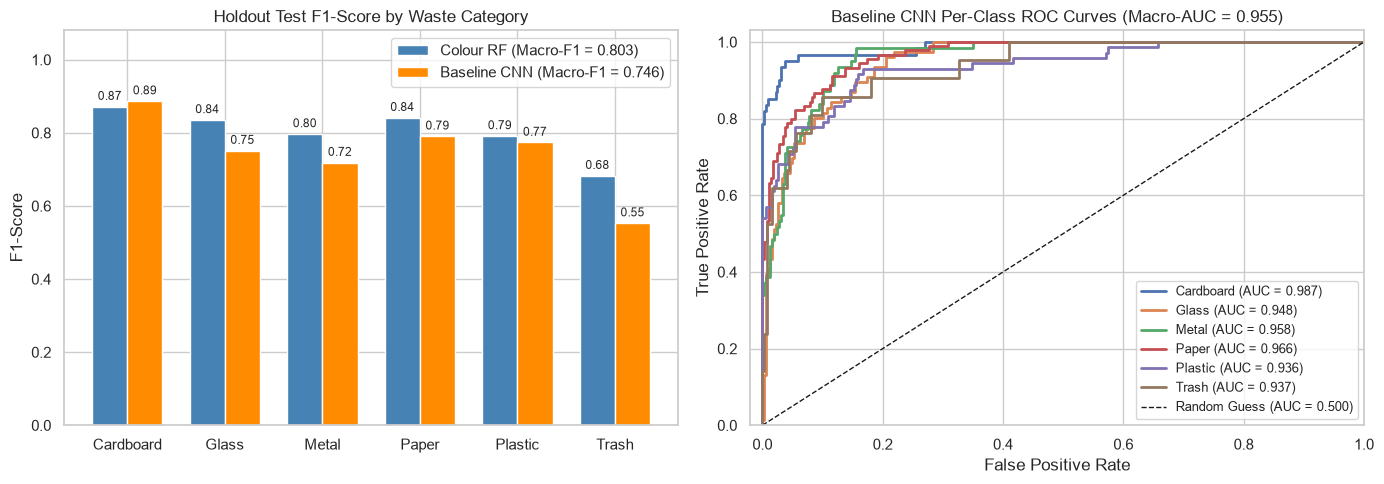

In [16]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Compute per-class F1 scores for both models on the 382 holdout test images
cnn_per_f1 = f1_score(y_true, y_pred, average=None)
rf_per_f1  = f1_score(y_true, rf_test_pred, average=None)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left Panel: Per-Class F1-Score Bar Chart (Colour RF vs. Baseline CNN) ---
x = np.arange(len(CLASSES))
width = 0.36
rects1 = axes[0].bar(x - width/2, rf_per_f1, width, label=f"Colour RF (Macro-F1 = {rf_test_f1:.3f})", color="steelblue")
rects2 = axes[0].bar(x + width/2, cnn_per_f1, width, label=f"Baseline CNN (Macro-F1 = {cnn_test_f1:.3f})", color="darkorange")

axes[0].bar_label(rects1, fmt="%.2f", padding=3, fontsize=8.5)
axes[0].bar_label(rects2, fmt="%.2f", padding=3, fontsize=8.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels([c.capitalize() for c in CLASSES])
axes[0].set_ylim(0, 1.08)
axes[0].set_ylabel("F1-Score")
axes[0].set_title("Holdout Test F1-Score by Waste Category")
axes[0].legend(loc="upper right")

# --- Right Panel: Per-Class One-vs-Rest ROC Curves (Baseline CNN) ---
y_true_bin = label_binarize(y_true, classes=np.arange(len(CLASSES)))
for i, cls_name in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], test_probs[:, i])
    cls_auc = auc(fpr, tpr)
    axes[1].plot(fpr, tpr, lw=2, label=f"{cls_name.capitalize()} (AUC = {cls_auc:.3f})")

axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random Guess (AUC = 0.500)")
axes[1].set_xlim([-0.02, 1.0])
axes[1].set_ylim([0.0, 1.03])
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title(f"Baseline CNN Per-Class ROC Curves (Macro-AUC = {cnn_test_auc:.3f})")
axes[1].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "10fold_per_class_f1_and_roc.png", dpi=150)
plt.show()


### Observations from Per-Category F1 & ROC Curves 
* **Category-by-category F1 comparison (Left chart):**
  * Baseline CNN wins on 'Cardboard' (0.89 vs 0.87) and is very close on 'Plastic' (0.77 vs 0.79) and 'Paper' (0.79 vs 0.84).
  * **Colour Random Forest leads on reflective/transparent and rare categories:** 'Glass'(0.84 vs 0.75), Metal (0.80 vs 0.72) and 'Trash' (0.68 vs 0.55).
* **Strong probability ranking across every category (Right chart — ROC curves):**
  * Every class curve rises sharply toward the top-left corner well above the dashed random-guess line (0.500): Cardboard (0.987), Paper (0.966), Metal (0.958), Glass (0.948), Trash (0.937) and Plastic (0.936) averaging to Macro-AUC = 0.955.


## 7. Summary & Key Conclusions

### 1. Model Stability (10-Fold Stratified Cross-Validation on 2,142 Images)

| Model | 10-Fold Val Macro-AUC (Mean ± Std) | 10-Fold Val Macro-F1 (Mean ± Std) | Holdout Test Macro-AUC | Holdout Test Macro-F1 |
| :--- | :---: | :---: | :---: | :---: |
| **Colour Random Forest** | 0.957 ± 0.010 | 0.762 ± 0.028 | 0.964 | 0.803 |
| **Baseline CNN (Scratch)** | 0.950 ± 0.009 | 0.721 ± 0.036 | 0.955 | 0.746 |

* **Macro-AUC is stable across splits:** The CNN's validation Macro-AUC varied by only ± 0.009 across the 10 folds, whereas Macro-F1 varied more (± 0.036). Because each fold chose its best epoch using its validation AUC, the CNN's CV scores are slightly optimistic.
* **Holdout test results match the CV estimate:** After final full-data training on all 2,142 development images for 43 epochs the final CNN achieved 0.955 Macro-AUC and 0.746 Macro-F1 (76.7% accuracy) on the 382 holdout test images.

---

### 2. Error Analysis from the Test Confusion Matrix
* **Strongest classes:** cardboard (F1 = 0.887, outperforming the Colour RF's 0.87) followed by paper (0.791) and plastic (0.774).
* **Largest confusions:** metal → glass (10 images), plastic → glass (8 images) and paper → metal (8 images). Together, these three pairs account for 26 of the 89 total test errors, driven mainly by studio glare and surface reflections.
* **Class imbalance:** trash (only 21 test images) had the lowest F1 (0.553) and precision (0.500) though its ROC AUC (0.937) shows strong probability ranking despite limited training examples.

---

### 3. Does a Small Scratch CNN Beat Colour Alone?
* **No.** On Macro-AUC, both models perform nearly identically (CV 0.950 vs 0.957, smaller than the fold-to-fold spread). On Macro-F1, the Colour Random Forest stays ahead (CV 0.762 vs 0.721, winning in 8 of 10 folds and holdout test 0.803 vs 0.746).
* **Next step:** Training from scratch on 2,142 images limits how much fine-grained texture the CNN can learn, making "transfer learning" with a pretrained backbone (such as ResNet18 or MobileNetV3) the logical next step.


### Data Leakage and Limitations
- **Leakage prevention checked:** Exact duplicate images were removed before splitting, in every fold, RGB normalization statistics and class weights were calculated using that fold's training images only, the 382 image holdout test set was kept completely locked away until Section 6.
- **Epoch selection optimism:** In each CV fold, the best checkpoint was chosen using that fold's validation AUC, so the CNN's cross-validation scores may be slightly optimistic compared to the Colour Random Forest, which does not require epoch selection.
- **Overlapping training folds:** Because any two CV training folds share 8 of their 9 training slices (89% of their images) the folds are not statistically independent meaning the standard deviation describes fold to fold spread rather than a formal confidence interval (and each validation fold contains only 11–12 'trash' images).
- **Image-level splitting:** Because TrashNet splits at the image level rather than grouping multiple photos of the same physical object together, different angles of the same item could appear across splits, slightly inflating scores for both models.

